In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
diabetes = load_diabetes()

X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = diabetes.target

print("First Five Records:")
print(X.head())

print("\nTarget Values:")
print(y[:5])

First Five Records:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  

Target Values:
[151.  75. 141. 206. 135.]


In [3]:
print("Dataset Shape:")
print(X.shape)

print("\nFeature Names:")
print(X.columns.tolist())

print("\nStatistical Summary:")
print(X.describe())

print("\nMissing Values:")
print(X.isnull().sum().sum())

print("\nDuplicate Rows:")
print(X.duplicated().sum())

Dataset Shape:
(442, 10)

Feature Names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Statistical Summary:
                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164e-02 -9.027530e-02 -1.123988e-01 -1.267807e-01   
25%   -3.729927e-02 -4.464164e-02 -3.422907e-02 -3.665608e-02 -3.424784e-02   
50%    5.383060e-03 -4.464164e-02 -7.283766e-03 -5.670422e-03 -4.320866e-03   
75%    3.807591e-02  5.068012e-02  3.124802e-02  3.564379e-02  2.835801e-02   
max    1.107267e-01  5.068012e-02  1.705552e-01  1.320436e-01  1.539137e-01   

                 s2            s3            s4            s5            s6  
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  
mean 

In [4]:
X = X
y = y

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (353, 10)
Testing Features Shape: (89, 10)
Training Target Shape: (353,)
Testing Target Shape: (89,)


In [5]:
model = LinearRegression()

model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training MSE:", round(train_mse, 2))
print("Testing MSE:", round(test_mse, 2))

print("Training R2 Score:", round(train_r2, 3))
print("Testing R2 Score:", round(test_r2, 3))

Training MSE: 2868.55
Testing MSE: 2900.19
Training R2 Score: 0.528
Testing R2 Score: 0.453


In [6]:
degrees = [1, 2, 3, 5]

results = []

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    results.append({
        "Degree": degree,
        "Training MSE": train_mse,
        "Testing MSE": test_mse
    })

    print("Polynomial Degree:", degree)
    print("Training MSE:", round(train_mse, 2))
    print("Testing MSE:", round(test_mse, 2))
    print("-" * 30)

Polynomial Degree: 1
Training MSE: 2868.55
Testing MSE: 2900.19
------------------------------
Polynomial Degree: 2
Training MSE: 2393.14
Testing MSE: 3096.03
------------------------------
Polynomial Degree: 3
Training MSE: 745.62
Testing MSE: 82446.05
------------------------------
Polynomial Degree: 5
Training MSE: 0.0
Testing MSE: 143012.59
------------------------------


In [7]:
results_df = pd.DataFrame(results)

print("Model Performance Comparison:")
print(results_df.round(2))

Model Performance Comparison:
   Degree  Training MSE  Testing MSE
0       1       2868.55      2900.19
1       2       2393.14      3096.03
2       3        745.62     82446.05
3       5          0.00    143012.59


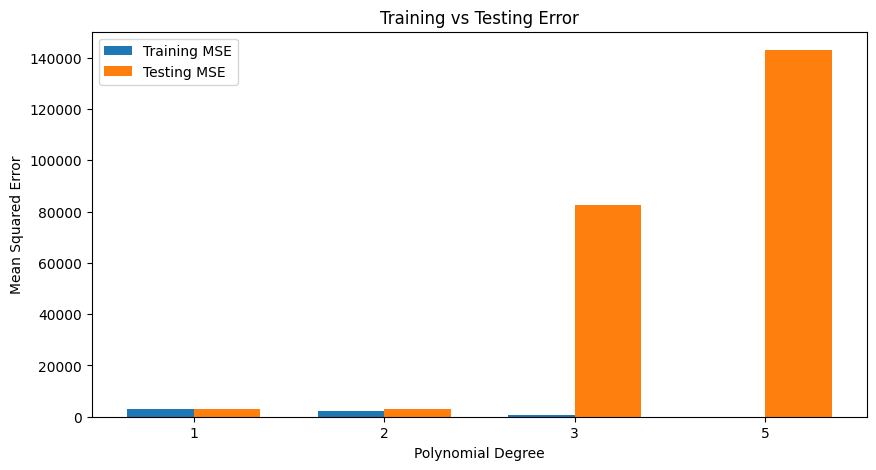

In [8]:
plt.figure(figsize=(10, 5))

x = np.arange(len(results_df))
width = 0.35

plt.bar(x - width/2, results_df["Training MSE"], width, label="Training MSE")
plt.bar(x + width/2, results_df["Testing MSE"], width, label="Testing MSE")

plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title("Training vs Testing Error")
plt.xticks(x, results_df["Degree"])
plt.legend()
plt.show()

In [9]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kf,
        scoring="neg_mean_squared_error"
    )

    mse_scores = -scores

    cv_results.append({
        "Degree": degree,
        "CV MSE": mse_scores.mean()
    })

    print("Polynomial Degree:", degree)
    print("Fold MSE Scores:", np.round(mse_scores, 2))
    print("Average CV MSE:", round(mse_scores.mean(), 2))
    print("-" * 30)

Polynomial Degree: 1
Fold MSE Scores: [2848.75 3221.81 2813.57 2965.9  3520.68]
Average CV MSE: 3074.14
------------------------------
Polynomial Degree: 2
Fold MSE Scores: [3529.96 4593.75 3708.22 3234.23 4565.4 ]
Average CV MSE: 3926.31
------------------------------
Polynomial Degree: 3
Fold MSE Scores: [21758003.86   871238.96  7842695.68  2206330.78  1441886.59]
Average CV MSE: 6824031.17
------------------------------
Polynomial Degree: 5
Fold MSE Scores: [189764.14 231645.46 162513.36 133256.41 181220.84]
Average CV MSE: 179680.04
------------------------------


In [10]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kf,
        scoring="neg_mean_squared_error"
    )

    mse_scores = -scores

    cv_results.append({
        "Degree": degree,
        "CV MSE": mse_scores.mean()
    })

    print("Polynomial Degree:", degree)
    print("Fold MSE Scores:", np.round(mse_scores, 2))
    print("Average CV MSE:", round(mse_scores.mean(), 2))
    print("-" * 30)

Polynomial Degree: 1
Fold MSE Scores: [2848.75 3221.81 2813.57 2965.9  3520.68]
Average CV MSE: 3074.14
------------------------------
Polynomial Degree: 2
Fold MSE Scores: [3529.96 4593.75 3708.22 3234.23 4565.4 ]
Average CV MSE: 3926.31
------------------------------
Polynomial Degree: 3
Fold MSE Scores: [21758003.86   871238.96  7842695.68  2206330.78  1441886.59]
Average CV MSE: 6824031.17
------------------------------
Polynomial Degree: 5
Fold MSE Scores: [189764.14 231645.46 162513.36 133256.41 181220.84]
Average CV MSE: 179680.04
------------------------------


In [11]:
cv_results_df = pd.DataFrame(cv_results)

print("Cross-Validation Results:")
print(cv_results_df.round(2))

comparison_df = pd.merge(
    results_df,
    cv_results_df,
    on="Degree"
)

print("\nComplete Model Comparison:")
print(comparison_df.round(2))

Cross-Validation Results:
   Degree      CV MSE
0       1     3074.14
1       2     3926.31
2       3  6824031.17
3       5   179680.04

Complete Model Comparison:
   Degree  Training MSE  Testing MSE      CV MSE
0       1       2868.55      2900.19     3074.14
1       2       2393.14      3096.03     3926.31
2       3        745.62     82446.05  6824031.17
3       5          0.00    143012.59   179680.04


In [12]:
for _, row in comparison_df.iterrows():
    degree = row["Degree"]
    train_error = row["Training MSE"]
    test_error = row["Testing MSE"]

    print("Polynomial Degree:", degree)

    if train_error > 10000 and test_error > 10000:
        print("Possible Underfitting: Both errors are high.")
    elif test_error > train_error * 1.5:
        print("Possible Overfitting: Testing error is much higher.")
    else:
        print("Reasonable Fit: Training and testing errors are relatively close.")

    print("-" * 40)

Polynomial Degree: 1.0
Reasonable Fit: Training and testing errors are relatively close.
----------------------------------------
Polynomial Degree: 2.0
Reasonable Fit: Training and testing errors are relatively close.
----------------------------------------
Polynomial Degree: 3.0
Possible Overfitting: Testing error is much higher.
----------------------------------------
Polynomial Degree: 5.0
Possible Overfitting: Testing error is much higher.
----------------------------------------


In [13]:
best_degree = cv_results_df.loc[
    cv_results_df["CV MSE"].idxmin(), "Degree"
]

print("Best Polynomial Degree:", best_degree)

best_model = make_pipeline(
    PolynomialFeatures(degree=int(best_degree)),
    LinearRegression()
)

best_model.fit(X_train, y_train)

final_predictions = best_model.predict(X_test)

final_mse = mean_squared_error(y_test, final_predictions)
final_r2 = r2_score(y_test, final_predictions)

print("Final Testing MSE:", round(final_mse, 2))
print("Final Testing R2 Score:", round(final_r2, 3))

Best Polynomial Degree: 1
Final Testing MSE: 2900.19
Final Testing R2 Score: 0.453
